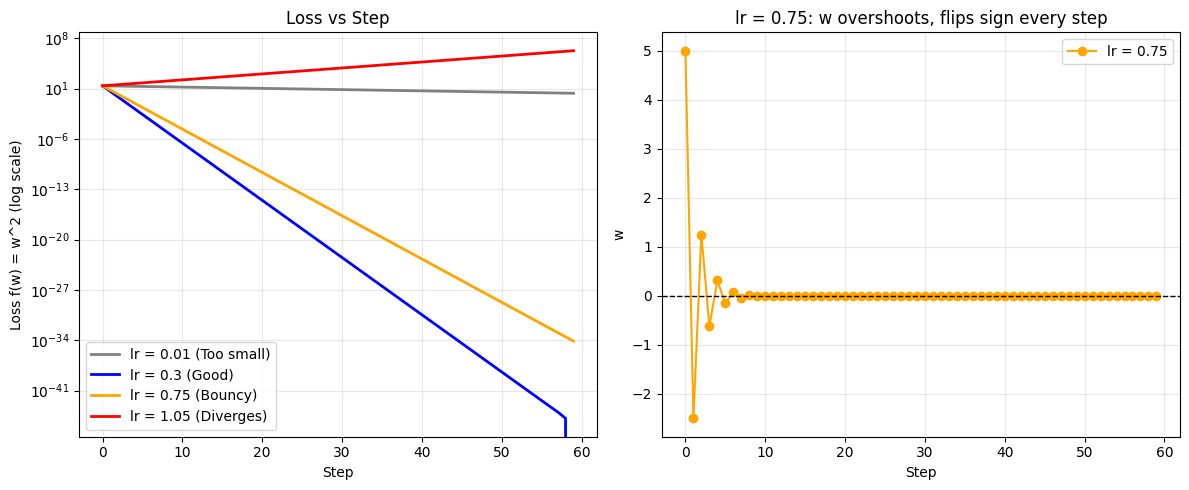

In [3]:
import torch
import matplotlib.pyplot as plt

# 1. Setup Data & Function
# Hum wahi function use kar rahe hain: f(w) = w^2
# Ideal minimum 0 par hai
def loss_function(w):
    return w**2

# 2. Hyperparameters
learning_rates = [0.01, 0.3, 0.75, 1.05] # Graph wale exact values
initial_w = 5.0
steps = 60

# Colors for graph (matching your screenshot)
colors = ['gray', 'blue', 'orange', 'red']
labels = ['lr = 0.01 (Too small)', 'lr = 0.3 (Good)', 'lr = 0.75 (Bouncy)', 'lr = 1.05 (Diverges)']

plt.figure(figsize=(12, 5))

# 3. Loop through each learning rate
for i, lr in enumerate(learning_rates):
    
    # A. Initialize weight with requires_grad=True (PyTorch ko bolo track kare)
    w = torch.tensor(initial_w, requires_grad=True)
    
    # Store history for plotting
    w_history = []
    loss_history = []
    
    # B. Training Loop (Manual Gradient Descent)
    for step in range(steps):
        # Forward pass: Calculate Loss
        loss = loss_function(w)
        
        # Save data for this step
        w_history.append(w.item())
        loss_history.append(loss.item())
        
        # Backward pass: Calculate Gradient (dJ/dw)
        loss.backward()
        
        # C. Optimizer Step: Update weight manually
        # PyTorch mein humein gradient ko 'torch.no_grad()' ke andar update karna hota hai
        with torch.no_grad():
            w -= lr * w.grad  # The formula: w = w - eta * gradient
            
        # Zero the gradient for the next step (warna wo add hota rahega)
        w.grad.zero_()
        
        # Agar diverge ho gaya (loss bahut bada ho gaya), toh loop break kar do
        if abs(w.item()) > 1e5: 
            break

    # 4. Plotting results for this specific learning rate
    # Left Graph: Loss vs Step
    plt.subplot(1, 2, 1)
    plt.plot(loss_history, label=labels[i], color=colors[i], linewidth=2)
    plt.yscale('log') # Log scale because loss goes down to 10^-48
    plt.title('Loss vs Step')
    plt.xlabel('Step')
    plt.ylabel('Loss f(w) = w^2 (log scale)')
    plt.legend()
    plt.grid(True, alpha=0.3)

    # Right Graph: w vs Step (Only for lr=0.75 to show bouncing)
    if lr == 0.75:
        plt.subplot(1, 2, 2)
        plt.plot(w_history, marker='o', color='orange', label=f'lr = {lr}')
        plt.axhline(0, color='black', linestyle='--', linewidth=1) # Zero line
        plt.title('lr = 0.75: w overshoots, flips sign every step')
        plt.xlabel('Step')
        plt.ylabel('w')
        plt.legend()
        plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()